# 63장 · RAG 서비스 함수와 응답 계약

서비스 함수는 검색과 답변 생성을 호출자가 사용할 한 가지 인터페이스로 묶습니다. 근거가 없는 경우에도 일관된 형식으로 결과를 돌려줍니다.

‘과제는 어디에 내나요?’라는 질문을 받았습니다. 이제까지 배운 검색·근거 표시·사용자별 대화를 한 서비스 함수에서 이어 봅니다. 질문과 출처는 기존 과정 안내 예제를 그대로 사용합니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## search()의 입력 문서와 조회 결과

문서 번호와 페이지는 역할이 다릅니다. course-guide-v1:p2는 자료를 구별하는 ID이고 이 문장이 인쇄된 쪽은 1쪽입니다. 답변과 출처를 같은 원문에서 가져오면 다음 단계에서 다시 대조할 수 있습니다.


### 셀 01 · search()의 문서 검색

한 문서만 있는 작은 검색입니다. 저장한 자료를 어떤 질문에 반환할지 확인하세요.


In [1]:
document = {"id": "course-guide-v1:p2", "source": "가상 과정 운영 안내 · 45일 수업용 페이지판 (source-pages.html)",
            "page": 1, "text": "과제는 학습 관리 페이지의 과제함에 제출합니다. 제출 뒤 파일 이름과 등록 시간을 확인합니다."}

def search(question):
    return [document] if "과제" in question else []

print(search("과제는 어디에 내나요?")[0]["text"])

과제는 학습 관리 페이지의 과제함에 제출합니다. 제출 뒤 파일 이름과 등록 시간을 확인합니다.


과제함이라는 답과 제출 후 확인할 두 항목을 모두 원문에서 찾을 수 있습니다. 여기서 쓰는 검색은 키워드 하나만 보는 수업용 함수입니다.


### 문서 ID와 페이지의 표기

<p>문서의 id는 course-guide-v1:p2이고 page 필드의 값은 1입니다. 코드가 출력하는 정수와 사람이 보는 ID 안의 표기를 그대로 구분해서 읽습니다.</p>


## answer()의 상태·답변·출처

정상 실행에도 근거가 없을 수 있습니다. 앱이 읽는 run_status에는 실행 상황을, result.status에는 답변을 만들었는지 적습니다. 소유 대화인지 확인한 뒤에만 검색하고, 빈 결과에서는 생성 횟수를 늘리지 않습니다.

<!-- lesson-visual detail-envelope -->
**실행은 완료됐는데 답변은 왜 없을까요?**

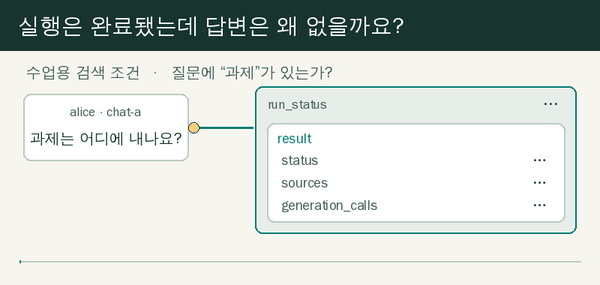

alice의 chat-a에서 같은 함수를 두 번 호출한 경우입니다. 두 요청 모두 run_status는 completed지만, 주차 질문은 근거가 없어 result.status가 no_evidence이고 생성은 0회입니다.
<!-- /lesson-visual detail-envelope -->


### 소유자 확인을 지나 원문과 인용이 답변이 될 때

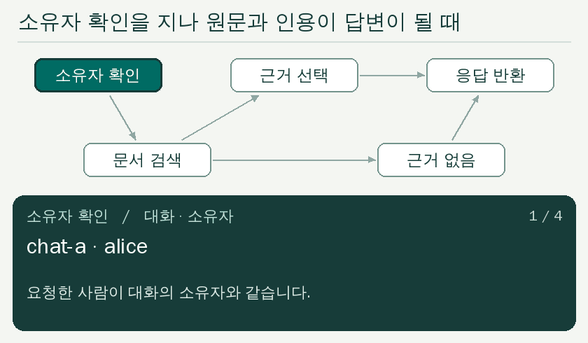

이 예제의 answer는 로컬 함수입니다. 답변과 generation_calls 필드를 노트북에서 어떻게 만드는지 보세요.


### 셀 02 · answer()의 응답 계약

제공 서비스의 읽기 경로를 줄인 함수입니다. 이 요청의 답과 출처 쪽수를 확인하세요.

소유자가 맞지 않으면 조회를 계속하기 전에 거부합니다. 허용된 소유자에게서 검색이 빈 경우에는 근거 부족 결과로 끝납니다. 문서를 찾은 경우에만 그 원문을 건네 답을 만듭니다. 세 경우의 마지막 줄을 각각 찾아보세요.


In [2]:
owners = {"chat-a": "alice"}
def answer(question, *, owner, conversation):
    if owners.get(conversation) != owner:
        raise PermissionError("conversation_not_owned")
    docs = search(question)
    if not docs:
        return {"run_status": "completed", "result": {"status": "no_evidence", "answer": "자료에서 확인할 수 없습니다.", "sources": [], "generation_calls": 0}}
    doc = docs[0]
    result = {"status": "answered", "answer": f"{doc['text']} [{doc['id']}]",
              "sources": [doc], "generation_calls": 1}
    return {"run_status": "completed", "result": result}

row = answer("과제는 어디에 내나요?", owner="alice", conversation="chat-a")
print(row["result"]["answer"])
print(row["result"]["sources"][0]["page"])

과제는 학습 관리 페이지의 과제함에 제출합니다. 제출 뒤 파일 이름과 등록 시간을 확인합니다. [course-guide-v1:p2]
1


답변 끝에 문서 ID가 붙고 다음 줄에는 1이 나옵니다. generation_calls는 이 축약 예제의 고정 답변 생성 경로에 들어간 횟수입니다. 실제 모델 호출은 없습니다.


### 처리 결과와 답변 상태를 따로 읽기

<p>run_status는 요청 처리가 끝났는지를, result.status는 문서로 답할 수 있었는지를 나타냅니다. 주차 질문은 처리가 끝나도 no_evidence입니다.</p>


### 검색보다 먼저 확인하는 소유자

<p>answer는 owners에서 대화의 소유자를 조회해 전달받은 owner와 비교합니다. 일치하지 않으면 PermissionError가 발생하므로 search가 그 요청의 자료를 읽지 않습니다.</p>


### 생성 횟수 필드 읽기

<p>이 셀은 문서 한 건이 있으면 f 문자열로 답변을 만들고 generation_calls에 1을 적습니다. 외부 모델의 실제 사용량을 측정한 값은 아닙니다.</p>


### 과제 03 · 근거 부재 시 생성 생략

같은 사용자가 주차비를 물었습니다. 결과 상태와 생성 횟수를 꺼내세요.


In [3]:
# answer에 주차 질문을 전달하고 result를 확인하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>missing = answer(&#x27;주차는 무료인가요?&#x27;, owner=&#x27;alice&#x27;, conversation=&#x27;chat-a&#x27;)[&#x27;result&#x27;]
print(missing[&#x27;status&#x27;], missing[&#x27;generation_calls&#x27;])</code></pre>
<p>실행 결과</p><pre><code>no_evidence 0</code></pre>
<p>no_evidence 0입니다. 주차비가 0원이라는 답과는 다릅니다. DB나 MCP 없이도 이 질문에서 필요한 기능을 완성할 수 있습니다.</p>
</details>


### 근거가 없을 때의 분기

<p>주차 질문에는 ‘과제’가 없어 search가 빈 리스트를 돌려줍니다. answer는 즉시 sources=[]와 generation_calls=0을 반환합니다. 원문 없이 제출 방법을 추측하는 단계는 없습니다.</p>

<h3>소유자 확인 뒤에 나뉘는 검색 경로</h3>

<p>answer는 대화 소유자가 다르면 search를 호출하기 전에 PermissionError를 냅니다. alice가 chat-a에서 과제 질문을 하면 문서 course-guide-v1:p2를 담아 answered를 반환합니다. 같은 대화에 주차 질문을 보내면 빈 검색 결과에서 즉시 no_evidence와 generation_calls=0을 반환합니다.</p>


### 질문이 주차로 바뀌면 검색에서 끝나는 경로

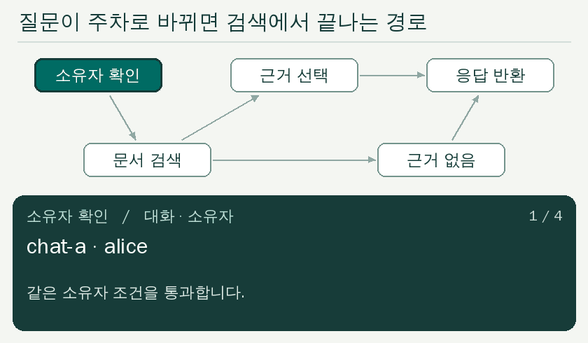

검색이 정상 종료된 빈 결과입니다. 작성 단계에 전달할 자료가 없으므로 답변 생성 횟수는 0입니다.


## 돌아보기

이 서비스에 문의 등록 버튼을 붙이면 데이터를 바꾸는 일이 생깁니다. 누가 무슨 내용을 등록하려는지 보여 주는 단계는 어디에 넣을지 생각해 보세요.

### 필수 검색의 결과와 종료

**소유자와 입력 확인**　질문·k와 대화 소유자가 유효해야 검색합니다.

```
invalid input → 실행 오류
```

**검색과 R1 검사**　한 번 검색하고 출처 객체·개수 계약을 확인합니다.

```
mandatory_retrieval_calls = 1
```

**빈 결과로 종료**　문서가 []이면 모델과 생성은 호출하지 않습니다.

```
주차 질문 → no_evidence · 생성 0회
```

**문서를 찾은 경우**　주차 질문을 마친 뒤의 단계가 아닙니다. 과제 질문으로 새로 실행한 경우입니다.

```
과제 질문 → course-guide-v1:p2
```
